# Deep Learning in Human Languague Technology course project 2026
*   Student name: Lasse Nordqvist
*   Date: 10.11.2026
*   Chosen corpuses: AGNews for binary taks and DBClasses for multilabel class




**Use of generative AI tools in this project**<br><br>
Generative AI was used in this project to suggest different prompting strategies that should be examined in this project. It was also used to help in preprocessing the data into the training, validation, and test splits defined by the author, defining the evaluation methods for the SmolLM and BERT models, and instruct how the models were efficiently fine-tuned with Colab GPUs.<br><br>
**Purpose and implementation of project**<br><br>
The purpose of this project is to test the performance of the encoder-only BERT base model and the decoder-only SmolLM-135M model on a binary classification task of classifying articles into sports and non-sports articles. The following ten techniques are implemented to examine the performance of the models:

1.   Baseline performance of the SmolLM model with positive question framing
1.   Baseline performance of the SmolLM model with negative question framing
1.   One-shot prompting the SmolLM model with instructions first
1.   Few-shot prompting the SmolLM model with instructions first
1.   One-shot prompting the SmolLM model with examples first
2.   Few-shot prompting the SmolLM model with examples first
1.   Role prompting the SmolLM model
2.   Fine-tuning the SmolLM model with learning rate hyperparameter optimization
1.   Baseline performance of the BERT model (no fine-tuning)
1.   Fine-tuning the BERT model with learning rate hyperparameter optimization

In a recent article, [1] examined the performance of decoder-only and encoder-only models on various text classification tasks. They conclude that fine-tuned encoder-only models exceed the performance of decoder-only models in text classification tasks, given that enough training data is available. Thus, it is expected that the strategies 9 and 10 would reach the highest performance.

The effect of question framing is examined for the baseline performance of the SmolLM model, as question framing has had an effect with modern LLMs [2]. One-shot prompting, few-shot prompting, and role-prompting are viable prompting strategies to increase the performance of small language models in various tasks [3-5]. Fine-tuning pre-trained general transformer models for a specific task has also been found to increase their performance in said tasks, both for bi-directional transformer models [6-7] and small language models [8]. Thus, these strategies are implemented to examine if they increase the performance of the transformer models in binary classification task.<br><br>

**Project Dataset**<br><br>
The dataset used in this project is the AG News Dataset available on Kaggle and Huggingface. The original corpus includes over a million news articles gathered from over 2 000 sources. A text classification dataset has been constructed divided into four broad categories that have been covered the most in the original corpus: World, Sport, Business, Sci/Tech. Each class has 30 000 training examples and 1 900 test examples in the dataset [9-10]. To suit the binary classification task of this project, a soft One-vs-Rest approach is adopted, meaning the labels of World, Business, and Sci/Tech articles are changed to 'Other', with 'Sports' articles being designated the positive class and 'Other' articles the negative class.<br><br>

**Performance evaluation baseline performance**<br><br>

The AG news dataset has primarily been utilized for multi-class classification, as the dataset contains four distinct classes. Using a heavily biased training set where 1% of the training examples represented the target class, [11] were able to reach a F1 score of 0.7 in binary classification task, where a CB-DAL v2 machine learning model was tasked to classify if test articles belonged to the 'World' class or not. [2] examined how the framing effect, a known cognitive bias where the framing of questions affects the responses of individuals, affects the performance of LLMs. They employed a soft One-vs-Rest approach and tasked various LLMs (GPT-3.5-Turbo, Llama-3-8B, Qwen-2.5-32B) to conduct binary classification for the four different categories. For the sports category, classification accuracy varied between 84.9% and 94.5% for the different models. Thus, for the classification results of this project to be viable, the different techniques should be able to reach an accuracy score in this range. <br><br>

In this project, the accuracy and macro F1 scores are employed as performance metrics. Accuracy measures how well the model is able to label data given to it overall, while the macro F1 score is based on the unweighted mean of F1 scores of single labels. The macro F1 score is included as a metric to assess if the model is able to classify both sports and non-sports articles correctly [12-13].<br><br>

**Prompting generative AI models**<br><br>

When prompting generative AI models, the model should always be provided with a detailed description of the task it should execute. Especially for small language models it is key that explicit task instructions are included in the prompt to support task execution [5]. In this project, the SmolLM was prompted with the following task:<br><br>
"""<br>*Instruction: You are a text classifier. Classify the final article using exactly one of the following labels: 'Sports' or 'Other'. Do not provide any explanation.*<br>"""<br><br>

One-shot prompting and few-shot prompting are prompting strategies that present the model with representative examples of the different classes that are relevant to executing the task at hand [4-5]. In the context of binary classification examined in this project, an example prompt listing two sports articles and two non-sports articles would be:

<br>"""<br>*Instruction: You are a text classifier. Classify the final article using exactly one of the following labels: "Sports" or "Other". Do not provide any explanation, just the label.* <br><br>
*Article: Giddy Phelps Touches Gold for First Time – Michael Phelps won the gold medal in the 400 individual medley and set a world record in a time of 4 minutes 8.26 seconds.*<br>
*Label: Sports*<br><br>
*Article: Indians Mount Charge – The Cleveland Indians pulled within one game of the AL Central lead by beating the Minnesota Twins, 7-1, Saturday night with home runs by Travis Hafner and Victor Martinez.*<br>
*Label: Sports*<br><br>
*Article: Fears for T N pension after talks – Unions representing workers at Turner   Newall say they are 'disappointed' after talks with stricken parent firm Federal Mogul.*<br>
*Label: Other*<br><br>
*Article: IBM to hire even more new workers – By the end of the year, the computing giant plans to have its biggest headcount since 1991.*<br>
*Label: Other*<br><br>
*Article: [Test Article]*<br>
*Label:*<br>"""<br><br>

The order of the examples and instructions has been found to affect the performance of n-shot prompting especially for small language models [5]. Thus, n-shot prompting with the SmolLM model will be executed in both orders to examine if it has an effect on model performance in this specific task: both by first including the instructions and then the examples and vice-versa.<br><br>

Role prompting includes asserting the generative AI model with a role that is relevant in regards to the task at hand. The purpose of role prompting is to guide its reasoning in the task it will execute [3]. In this project, the role prompt given to the SmolLM language model is the following:<br><br>
"""<br>
*You are the senior sports editor at a national news outlet. Your job is to organize incoming stories. Determine if the following article belongs on the sports desk or another section. Classify the article using exactly one of the following labels: 'Sports' or 'Other'. Do not provide any explanation, just the label.*<br><br>
*Article: [Test Article]*<br>
*Label:*<br>"""<br><br>

**Fine-tuning models**<br><br>
Fine-tuning a pre-trained transformer model to a domain-specific task does not require extensive datasets, as the model performance converges relatively quickly. For a simple task such as a binary classificationm using less than a thousand examples is not yet enough to considerably increase the model performance, but a dataset of 6 000 examples already allows the model to reach robust classification results [11]. A train/validation/test split of 80/10/10 [14] with an even split between positive and negative examples [15] is commonly employed on datasets when fine-tuning pre-trained transformer models. To ensure fine-tuning consistency, the SmolLM model is fine-tuned using the same dataset. Thus, the fine-tuning of both models is executed with a subset of 6 000 examples from the AG news classification dataset, distributed as follows <br><br>
\begin{array}{c|ccc}
& \text{Training} & \text{Validation} & \text{Test} \\
\hline
\text{Sports articles} & 2 400 & 300 & 300 \\
\text{Non-sports articles} & 2 400 & 300 & 300  \\
\text{Total} & 4 800 & 600 & 600
\end{array}<br><br>
Hyperparameter optimization is conducted for the learning rate hyperparameter, as learning rate has been commonly identified as the most critical hyperparameter affecting the fine-tuning of pre-trained transformer models [16].










# 1. Setup

In [1]:
# Huggingface modules for downloading and manipulating dataset
from datasets import load_dataset, concatenate_datasets, DatasetDict
# Huggingface modules used to load model and tokenizer
from transformers import AutoTokenizer, AutoModelForSequenceClassification, DataCollatorWithPadding
# PyTorch
import torch
# Huggingface module for downloading causal generative models
from transformers import AutoModelForCausalLM, DataCollatorForLanguageModeling, pipeline
import numpy as np
# Accuracy and F1-scores used as performance metrics
from sklearn.metrics import accuracy_score, f1_score
# Huggingface modules for language model fine-tuning
from transformers import TrainingArguments, Trainer
# Libraries for visualizing results
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
# For applying Sigmoid activation to BERT logits in multi-label task
from scipy.special import expit


# 2. Data download, sampling and prepreprocessing



##2.1 Downloading the corpus

In [2]:
# Global random seed ensuring experiment reproducibility
SEED = 42

# Load AG News text classification dataset
raw_dataset = load_dataset("wangrongsheng/ag_news")

README.md:   0%|          | 0.00/8.07k [00:00<?, ?B/s]

data/train-00000-of-00001.parquet: reconstructing file:   0%|          |  0.00B / 18.6MB            

data/train-00000-of-00001.parquet: downloading bytes:           |  0.00B            

data/test-00000-of-00001.parquet: reconstructing file:   0%|          |  0.00B / 1.23MB            

data/test-00000-of-00001.parquet: downloading bytes:           |  0.00B            

Generating train split:   0%|          | 0/120000 [00:00<?, ? examples/s]

Generating test split:   0%|          | 0/7600 [00:00<?, ? examples/s]

##2.2 Sampling and preprocessing

In [3]:
# Map labels to binary (Class 1 = Sports, Classes 0, 2, 3 = Other)
def convert_to_binary(example):
    # Original AG News classes: 0=World, 1=Sports, 2=Business, 3=Sci/Tech
    example["label"] = 1 if example["label"] == 1 else 0
    return example

full_pool = raw_dataset["train"].map(convert_to_binary)

# Separate sports and non-sports, then shuffle with a fixed seed
sports_pool = full_pool.filter(lambda x: x["label"] == 1).shuffle(seed=SEED)
other_pool  = full_pool.filter(lambda x: x["label"] == 0).shuffle(seed=SEED)

# Select slices for a dataset of 6 000 examples with an 80/10/10 split and 50/50
# split between positive and negative examples
sports_train = sports_pool.select(range(0, 2400))
sports_val   = sports_pool.select(range(2400, 2700))
sports_test  = sports_pool.select(range(2700, 3000))

other_train  = other_pool.select(range(0, 2400))
other_val    = other_pool.select(range(2400, 2700))
other_test   = other_pool.select(range(2700, 3000))

# Combine sports and non-sports for each split and shuffle again
train_ds = concatenate_datasets([sports_train, other_train]).shuffle(seed=SEED)
val_ds   = concatenate_datasets([sports_val, other_val]).shuffle(seed=SEED)
test_ds  = concatenate_datasets([sports_test, other_test]).shuffle(seed=SEED)

# Package into a unified DatasetDict
final_dataset = DatasetDict({
    "train": train_ds,
    "validation": val_ds,
    "test": test_ds
})

# Verify class balances across splits
for split_name, split_data in final_dataset.items():
    sports_count = sum(1 for x in split_data["label"] if x == 1)
    other_count  = sum(1 for x in split_data["label"] if x == 0)
    print(f"[{split_name.upper()}] Total: {len(split_data)} | Sports: {sports_count} | Other: {other_count}")

# Format texts and prompts
def format_input_text(example):
    label_str = "Sports" if example["label"] == 1 else "Other"

    # Input prompt for inference/evaluation
    example["input_prompt"] = (
        f"Article: {example['text']}\n"
        f"Label:"
    )

    # Full prompt with target label for generative fine-tuning
    example["full_prompt"] = (
        f"Article: {example['text']}\n"
        f"Label: {label_str}"
    )

    example["label_str"] = label_str
    return example

# Apply across your DatasetDict
final_dataset = final_dataset.map(format_input_text)

Map:   0%|          | 0/120000 [00:00<?, ? examples/s]

Filter:   0%|          | 0/120000 [00:00<?, ? examples/s]

Filter:   0%|          | 0/120000 [00:00<?, ? examples/s]

[TRAIN] Total: 4800 | Sports: 2400 | Other: 2400
[VALIDATION] Total: 600 | Sports: 300 | Other: 300
[TEST] Total: 600 | Sports: 300 | Other: 300


Map:   0%|          | 0/4800 [00:00<?, ? examples/s]

Map:   0%|          | 0/600 [00:00<?, ? examples/s]

Map:   0%|          | 0/600 [00:00<?, ? examples/s]

# 3. Prompting SmolLM

## 3.1. Preparing model

In [6]:
# Device configuration (uses GPU if available in Colab)
device = "cuda" if torch.cuda.is_available() else "cpu"

smollm_name = "HuggingFaceTB/SmolLM-135M-Instruct"

# Load SmolLM tokenizer
smollm_tokenizer = AutoTokenizer.from_pretrained(smollm_name)

# Assigning End-Of-Sequence token to act as the pad token.
if smollm_tokenizer.pad_token is None:
    smollm_tokenizer.pad_token = smollm_tokenizer.eos_token

# Tokenization function
def tokenize_smollm(example):
    return smollm_tokenizer(example["full_prompt"], truncation=True, max_length=512)

# Apply tokenization to the dataset
smollm_tokenized_ds = final_dataset.map(tokenize_smollm, batched=True)

# Load model with a causal LM head and load weights in 16-bit for efficient GPU usage
smollm_model = AutoModelForCausalLM.from_pretrained(smollm_name,torch_dtype=torch.float16)
smollm_model.to(device)

# Data collator
smollm_collator = DataCollatorForLanguageModeling(tokenizer=smollm_tokenizer, mlm=False)

# Defining SmolLM text-generation pipeline
pipe = pipeline(
    "text-generation",
    model=smollm_model,
    tokenizer=smollm_tokenizer,
    device=0 if device == "cuda" else -1,
    max_new_tokens=2,      # Max 2 tokens needed ('Sports' or 'Other')
    do_sample=False,       # Greedy decoding to ensure deterministic answers
    pad_token_id=smollm_tokenizer.eos_token_id
)

Loading weights:   0%|          | 0/272 [00:00<?, ?it/s]

##3.2 Prompt optimization

In [7]:
# Separate the training set into sports and other
train_sports = final_dataset["train"].filter(lambda x: x["label"] == 1)
train_other  = final_dataset["train"].filter(lambda x: x["label"] == 0)

# Extract exactly two sports examples and two other examples
sports_sample_1 = train_sports[0]
sports_sample_2 = train_sports[1]

other_sample_1 = train_other[0]
other_sample_2 = train_other[1]

# Format examples for n-shot prompting
ex_sports_1 = f"Article: {sports_sample_1['text']}\nLabel: Sports\n\n"
ex_sports_2 = f"Article: {sports_sample_2['text']}\nLabel: Sports\n\n"
ex_other_1  = f"Article: {other_sample_1['text']}\nLabel: Other\n\n"
ex_other_2  = f"Article: {other_sample_2['text']}\nLabel: Other\n\n"

# Base Instructions
inst_base = "Instruction: You are a text classifier. Classify the final article using exactly one of the following labels: 'Sports' or 'Other'. Do not provide any explanation.\n\n"
inst_pos = "Instruction: You are a text classifier. Classify the following article using exactly one of the following labels: 'Yes' if it is a sports article, or 'No' if it is not.\n\n"
inst_neg = "Instruction: You are a text classifier. Classify the following article using exactly one of the following labels: 'Yes' if it is a non-sports article, or 'No' if it is a sports article.\n\n"
inst_role = "You are the senior sports editor at a national news outlet. Your job is to organize incoming stories. Determine if the following article belongs on the sports desk or another section. Classify the article using exactly one of the following labels: 'Sports' or 'Other'. Do not provide any explanation, just the label.\n\n"

# Strategy 1: Positive framing baseline
def prompt_strat_1(example):
    return f"{inst_pos}Article: {example['text']}\nLabel:"

# Strategy 2: Negative framing baseline
def prompt_strat_2(example):
    return f"{inst_neg}Article: {example['text']}\nLabel:"

# Strategy 3: 1-Shot with instructions first
def prompt_strat_3(example):
    return f"{inst_base}{ex_sports_1}Article: {example['text']}\nLabel:"

# Strategy 4: Few-Shot with instructions first
def prompt_strat_4(example):
    return f"{inst_base}{ex_sports_1}{ex_other_1}{ex_sports_2}{ex_other_2}Article: {example['text']}\nLabel:"

# Strategy 5: 1-Shot with examples first
def prompt_strat_5(example):
    return f"{ex_sports_1}{inst_base}Article: {example['text']}\nLabel:"

# Strategy 6: Few-Shot with examples first
def prompt_strat_6(example):
    return f"{ex_sports_1}{ex_other_1}{ex_sports_2}{ex_other_2}{inst_base}Article: {example['text']}\nLabel:"

# Strategy 7: Role Prompting
def prompt_strat_7(example):
    return f"{inst_role}Article: {example['text']}\nLabel:"

Filter:   0%|          | 0/4800 [00:00<?, ? examples/s]

Filter:   0%|          | 0/4800 [00:00<?, ? examples/s]

##3.3 Evaluation on test test

In [8]:
test_data = final_dataset["test"]
results = {}

# Evaluator for SmolLM
def evaluate_smollm(model, dataset, prompt_func, pipe, yes_no_mode=False):
    model.eval()

    # Prepare all prompts and true labels
    prompts = [prompt_func(example) for example in dataset]
    true_labels = [example["label"] for example in dataset]

    # Feed the entire list to the pipeline with a batch size to ensure efficient
    # GPU usage
    outputs = pipe(prompts, batch_size=16, return_full_text=False)

    predictions = []
    for out in outputs:
        # HuggingFace pipelines return a list of dicts for each prompt
        text = out[0]['generated_text'].strip()

        # Parse output based on the expected vocabulary
        if yes_no_mode:
            pred_label = 1 if "yes" in text.lower() else 0
        else:
            pred_label = 1 if "sports" in text.lower() else 0

        predictions.append(pred_label)

    acc = accuracy_score(true_labels, predictions)
    f1 = f1_score(true_labels, predictions, average="macro") # Macro F1 used
    return {"Accuracy": acc, "Macro F1": f1} # to see how well the model can separate

print("Evaluating Strategy 1: SmolLM Positive Frame...")
results["Strat 1 (SmolLM Pos Frame)"] = evaluate_smollm(smollm_model, test_data, prompt_strat_1, pipe, yes_no_mode=True)

print("Evaluating Strategy 2: SmolLM Negative Frame...")
# 'Yes' means 'Other' in the negative frame, prediction parsing is inverted inside this loop
# by checking for 'no' as the sports identifier.
def eval_negative_frame(model, tokenizer, dataset):
    pipe = pipeline("text-generation", model=model, tokenizer=tokenizer, device=0 if device == "cuda" else -1, max_new_tokens=2, do_sample=False)
    preds, trues = [], []
    for ex in dataset:
        out = pipe(prompt_strat_2(ex), return_full_text=False)[0]['generated_text'].strip()
        pred = 1 if "no" in out.lower() else 0
        preds.append(pred)
        trues.append(ex["label"])
    return {"Accuracy": accuracy_score(trues, preds), "Macro F1": f1_score(trues, preds, average="macro")}
results["Strat 2 (SmolLM Neg Frame)"] = eval_negative_frame(smollm_model, smollm_tokenizer, test_data)

print("Evaluating Strategy 3: SmolLM 1-Shot (Inst First)...")
results["Strat 3 (1-Shot Inst First)"] = evaluate_smollm(smollm_model, test_data, prompt_strat_3, pipe)

print("Evaluating Strategy 4: SmolLM Few-Shot (Inst First)...")
results["Strat 4 (Few-Shot Inst First)"] = evaluate_smollm(smollm_model, test_data, prompt_strat_4, pipe)

print("Evaluating Strategy 5: SmolLM 1-Shot (Ex First)...")
results["Strat 5 (1-Shot Ex First)"] = evaluate_smollm(smollm_model, test_data, prompt_strat_5, pipe)

print("Evaluating Strategy 6: SmolLM Few-Shot (Ex First)...")
results["Strat 6 (Few-Shot Ex First)"] = evaluate_smollm(smollm_model, test_data, prompt_strat_6, pipe)

print("Evaluating Strategy 7: SmolLM Role Prompting...")
results["Strat 7 (Role Prompting)"] = evaluate_smollm(smollm_model, test_data, prompt_strat_7, pipe)

Evaluating Strategy 1: SmolLM Positive Frame...
Evaluating Strategy 2: SmolLM Negative Frame...


[transformers] You seem to be using the pipelines sequentially on GPU. In order to maximize efficiency please use a dataset


Evaluating Strategy 3: SmolLM 1-Shot (Inst First)...
Evaluating Strategy 4: SmolLM Few-Shot (Inst First)...
Evaluating Strategy 5: SmolLM 1-Shot (Ex First)...
Evaluating Strategy 6: SmolLM Few-Shot (Ex First)...
Evaluating Strategy 7: SmolLM Role Prompting...


# 4. Fine-tuning SmolLM model

##4.1 Model training & hyperparameter optimization

In [11]:
# Hyperparameter optimization for SmolLM fine-tuning
print("\nConducting hyperparameter optimization for SmolLM fine-tuning...")

smollm_candidate_lrs = [3e-5, 5e-5, 1e-4]
best_smollm_f1 = -1.0
best_smollm_lr = None

def prompt_strat_8_finetuned(example):
    return example["input_prompt"]

for lr in smollm_candidate_lrs:
    print(f"\nTesting SmolLM with learning rate: {lr}")

    # Reload fresh base model to avoid weight accumulation across search trials
    trial_smollm = AutoModelForCausalLM.from_pretrained(smollm_name, torch_dtype=torch.float32).to(device)

    trial_args = TrainingArguments(
        output_dir=f"./tmp_smollm_{lr}",
        eval_strategy="epoch",
        learning_rate=lr,
        per_device_train_batch_size=8,
        per_device_eval_batch_size=8,
        num_train_epochs=3,
        weight_decay=0.01,
        logging_steps=100,
        fp16=True if device == "cuda" else False,
        save_strategy="no"
    )

    trial_trainer = Trainer(
        model=trial_smollm,
        args=trial_args,
        train_dataset=smollm_tokenized_ds["train"],
        eval_dataset=smollm_tokenized_ds["validation"],
        data_collator=smollm_collator,
    )

    trial_trainer.train()

    # Evaluate trial model on the validation set
    trial_pipe = pipeline(
        "text-generation",
        model=trial_smollm,
        tokenizer=smollm_tokenizer,
        device=0 if device == "cuda" else -1,
        max_new_tokens=2,
        do_sample=False,
        pad_token_id=smollm_tokenizer.eos_token_id
    )

    val_metrics = evaluate_smollm(trial_smollm, final_dataset["validation"], prompt_strat_8_finetuned, trial_pipe)
    val_f1 = val_metrics["Macro F1"]
    print(f"SmolLM LR {lr} -> Validation Macro F1: {val_f1:.4f}")

    # Track and retain only the best model state
    if val_f1 > best_smollm_f1:
        best_smollm_f1 = val_f1
        best_smollm_lr = lr
        smollm_model = trial_smollm
        pipe = trial_pipe

print(f"\nSmolLm best LR: {best_smollm_lr} with validation Macro F1: {best_smollm_f1:.4f}")


Conducting hyperparameter optimization for SmolLM fine-tuning...

Testing SmolLM with learning rate: 3e-05


Loading weights:   0%|          | 0/272 [00:00<?, ?it/s]

Epoch,Training Loss,Validation Loss
1,3.179708,3.177105
2,2.911843,3.126274
3,2.760970,3.127374


SmolLM LR 3e-05 -> Validation Macro F1: 0.9800

Testing SmolLM with learning rate: 5e-05


Loading weights:   0%|          | 0/272 [00:00<?, ?it/s]

Epoch,Training Loss,Validation Loss
1,3.129370,3.122509
2,2.768553,3.086291
3,2.547224,3.114325


SmolLM LR 5e-05 -> Validation Macro F1: 0.9800

Testing SmolLM with learning rate: 0.0001


Loading weights:   0%|          | 0/272 [00:00<?, ?it/s]

Epoch,Training Loss,Validation Loss
1,3.085186,3.072939
2,2.546463,3.066136
3,2.169254,3.180132


SmolLM LR 0.0001 -> Validation Macro F1: 0.9616

SmolLm best LR: 3e-05 with validation Macro F1: 0.9800


##4.2. Evaluation on test set

In [12]:
# Final evaluation of the best SmolLM model on the TEST set
print("Evaluating Strategy 8: SmolLM fine-tuning...")
results["Strat 8 (Fine-Tuned SmolLM)"] = evaluate_smollm(smollm_model, test_data, prompt_strat_8_finetuned, pipe)

Evaluating Strategy 8: SmolLM fine-tuning...


# 5. Fine-tuning BERT model

##5.1. Model training

In [22]:
bert_name = "google-bert/bert-base-cased"

# Load BERT tokenizer
bert_tokenizer = AutoTokenizer.from_pretrained(bert_name)

# Tokenization function
def tokenize_bert(example):
    return bert_tokenizer(example["text"], truncation=True, max_length=512)

# Apply tokenization to the dataset
bert_tokenized_ds = final_dataset.map(tokenize_bert, batched=True)

# Load Model with a Sequence Classification head
bert_model = AutoModelForSequenceClassification.from_pretrained(
    bert_name,
    num_labels=2, # Binary classification
    id2label={1: "Sports", 0: "Other"},
    label2id={"Sports": 1, "Other": 0}
)

# Ensure GPU usage
bert_model.to(device)

# Data Collator dynamically padding batches to the longest sequence
bert_collator = DataCollatorWithPadding(tokenizer=bert_tokenizer)

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

[transformers] BertForSequenceClassification LOAD REPORT from: google-bert/bert-base-cased
Key                                        | Status     | 
-------------------------------------------+------------+-
cls.seq_relationship.weight                | UNEXPECTED | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED | 
cls.predictions.transform.dense.weight     | UNEXPECTED | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED | 
cls.predictions.bias                       | UNEXPECTED | 
cls.seq_relationship.bias                  | UNEXPECTED | 
cls.predictions.transform.dense.bias       | UNEXPECTED | 
classifier.weight                          | MISSING    | 
classifier.bias                            | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


##5.2. Hyperparameter optimization

In [19]:
# Hyperparameter optimization for BERT
print("\nConducting hyperparameter optimization for BERT fine-tuning...")

bert_candidate_lrs = [1e-5, 2e-5, 5e-5]
best_bert_f1 = -1.0
best_bert_lr = None

def compute_metrics(eval_pred):
    logits, labels = eval_pred
    predictions = np.argmax(logits, axis=-1)
    acc = accuracy_score(labels, predictions)
    f1 = f1_score(labels, predictions, average="macro")
    return {"accuracy": acc, "f1": f1}

for lr in bert_candidate_lrs:
    print(f"\nTesting BERT with learning rate: {lr}")

    # Reload fresh base model head for each trial
    trial_bert = AutoModelForSequenceClassification.from_pretrained(
        bert_name,
        num_labels=2,
        id2label={1: "Sports", 0: "Other"},
        label2id={"Sports": 1, "Other": 0}
    ).to(device)

    trial_args = TrainingArguments(
        output_dir=f"./tmp_bert_{lr}",
        eval_strategy="epoch",
        learning_rate=lr,
        per_device_train_batch_size=16,
        per_device_eval_batch_size=16,
        num_train_epochs=3,
        weight_decay=0.01,
        logging_steps=100,
        fp16=True if device == "cuda" else False,
        save_strategy="no"
    )

    trial_trainer = Trainer(
        model=trial_bert,
        args=trial_args,
        train_dataset=bert_tokenized_ds["train"],
        eval_dataset=bert_tokenized_ds["validation"],
        data_collator=bert_collator,
        compute_metrics=compute_metrics
    )

    trial_trainer.train()

    # Evaluate trial model on the validation set
    val_eval = trial_trainer.evaluate(eval_dataset=bert_tokenized_ds["validation"])
    val_f1 = val_eval["eval_f1"]
    print(f"BERT LR {lr} -> validation Macro F1: {val_f1:.4f}")

    # Track and retain only the best model state
    if val_f1 > best_bert_f1:
        best_bert_f1 = val_f1
        best_bert_lr = lr
        bert_best_model = trial_bert

print(f"\n BERT best LR: {best_bert_lr} with validation Macro F1: {best_bert_f1:.4f}")


Conducting hyperparameter optimization for BERT fine-tuning...

Testing BERT with learning rate: 1e-05


Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

[transformers] BertForSequenceClassification LOAD REPORT from: google-bert/bert-base-cased
Key                                        | Status     | 
-------------------------------------------+------------+-
cls.seq_relationship.weight                | UNEXPECTED | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED | 
cls.predictions.transform.dense.weight     | UNEXPECTED | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED | 
cls.predictions.bias                       | UNEXPECTED | 
cls.seq_relationship.bias                  | UNEXPECTED | 
cls.predictions.transform.dense.bias       | UNEXPECTED | 
classifier.weight                          | MISSING    | 
classifier.bias                            | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


Epoch,Training Loss,Validation Loss,Accuracy,F1
1,0.101996,0.085826,0.981667,0.981664
2,0.050581,0.093005,0.981667,0.981664
3,0.025386,0.095110,0.981667,0.981664


Training Loss,Validation Loss,Epoch,Accuracy,F1
0.025386,0.095110,3,0.981667,0.981664


BERT LR 1e-05 -> validation Macro F1: 0.9817

Testing BERT with learning rate: 2e-05


... (6 outputs left out)

[transformers] BertForSequenceClassification LOAD REPORT from: google-bert/bert-base-cased
Key                                        | Status     | 
-------------------------------------------+------------+-
cls.seq_relationship.weight                | UNEXPECTED | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED | 
cls.predictions.transform.dense.weight     | UNEXPECTED | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED | 
cls.predictions.bias                       | UNEXPECTED | 
cls.seq_relationship.bias                  | UNEXPECTED | 
cls.predictions.transform.dense.bias       | UNEXPECTED | 
classifier.weight                          | MISSING    | 
classifier.bias                            | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


Epoch,Training Loss,Validation Loss,Accuracy,F1
1,0.108853,0.076204,0.983333,0.983329
2,0.055539,0.071820,0.983333,0.983332
3,0.016738,0.093602,0.978333,0.978330


Training Loss,Validation Loss,Epoch,Accuracy,F1
0.016738,0.093602,3,0.978333,0.978330


BERT LR 5e-05 -> validation Macro F1: 0.9783

 BERT best LR: 2e-05 with validation Macro F1: 0.9833


##5.3. Evaluation on test set

In [23]:
def evaluate_bert(model, dataset):
    model.eval()
    predictions, true_labels = [], []

    with torch.no_grad():
        for example in dataset:
            inputs = bert_tokenizer(example["text"], return_tensors="pt", truncation=True, max_length=512).to(device)
            outputs = model(**inputs)
            pred = torch.argmax(outputs.logits, dim=1).item()
            predictions.append(pred)
            true_labels.append(example["label"])

    acc = accuracy_score(true_labels, predictions)
    f1 = f1_score(true_labels, predictions, average="macro")
    return {"Accuracy": acc, "Macro F1": f1}

# Evaluation of BERT baseline performance
print("Evaluating Strategy 9: BERT Baseline (Untrained Head)...")
results["Strat 9 (BERT Baseline)"] = evaluate_bert(bert_model, test_data)


# Final evaluation of the best BERT model on the TEST set
print("Evaluating Strategy 10: BERT fine-tuned...")
results["Strat 10 (Fine-Tuned BERT)"] = evaluate_bert(bert_best_model, test_data)

Evaluating Strategy 9: BERT Baseline (Untrained Head)...
Evaluating Strategy 10: BERT fine-tuned...


# 6. Binary classification results and summary


--- FINAL PROJECT RESULTS ---
                        Strategy  Accuracy  Macro F1
0     Strat 1 (SmolLM Pos Frame)  0.560000  0.528100
1     Strat 2 (SmolLM Neg Frame)  0.498333  0.338401
2    Strat 3 (1-Shot Inst First)  0.760000  0.751012
3  Strat 4 (Few-Shot Inst First)  0.918333  0.918168
4      Strat 5 (1-Shot Ex First)  0.515000  0.376230
5    Strat 6 (Few-Shot Ex First)  0.571667  0.477244
6       Strat 7 (Role Prompting)  0.611667  0.548121
7    Strat 8 (Fine-Tuned SmolLM)  0.976667  0.976664
8        Strat 9 (BERT Baseline)  0.500000  0.333333
9     Strat 10 (Fine-Tuned BERT)  0.988333  0.988333


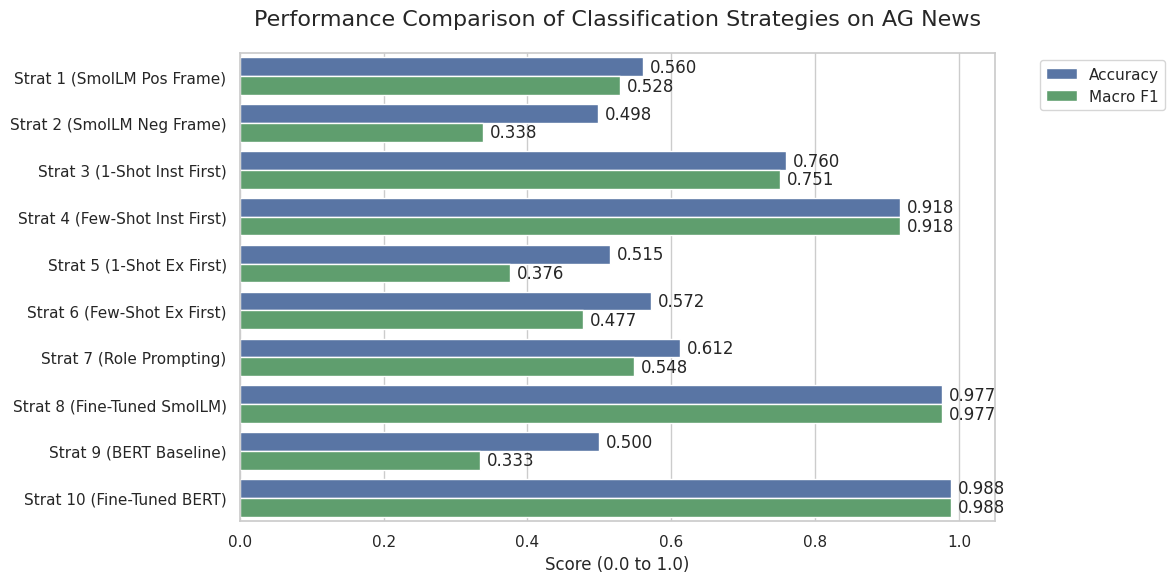

In [24]:
# Final Printout of all results

results_df = pd.DataFrame(results).T.reset_index()
results_df.columns = ['Strategy', 'Accuracy', 'Macro F1']
print("\n--- FINAL PROJECT RESULTS ---")
print(results_df)

plt.figure(figsize=(12, 6))
sns.set_theme(style="whitegrid")

# Grouped bar chart
df_melted = results_df.melt(id_vars='Strategy', value_vars=['Accuracy', 'Macro F1'], var_name='Metric', value_name='Score')
ax = sns.barplot(x='Score', y='Strategy', hue='Metric', data=df_melted, palette=['#4C72B0', '#55A868'])

plt.title('Performance Comparison of Classification Strategies on AG News', fontsize=16, pad=20)
plt.xlabel('Score (0.0 to 1.0)', fontsize=12)
plt.ylabel('', fontsize=12)
plt.xlim(0, 1.05)
plt.legend(title='', bbox_to_anchor=(1.05, 1), loc='upper left')

for container in ax.containers:
    ax.bar_label(container, fmt='%.3f', padding=5)

plt.tight_layout()
plt.savefig('classification_results.png', dpi=300, bbox_inches='tight')
plt.show()

##6.1 Corpus insights
This project shows that a multi-class dataset, such as the AG news dataset, can be converted to a binary classification task using the soft One-vs-Rest approach. However, the Sports articles included in the dataset were largely focused on US sports (Major League Baseball, National Basketball Association etc.). A similar project should be conducted for European sports articles to examine if the classification performance of the models differs on those.<br><br>


##6.2 Results
As can be seen from the results above, fine-tuning the SmolLM and BERT models reached the highest performance levels. These results support the findings of [1] that smaller language models exceed the text classification capabilities of larger ones when enough training data is available. These results also support the findings of [11] that a dataset of 6 000 exmaples is more than enough to fine-tune a pre-trained transformer model to a simple binary classification task.
The three baseline strategies show that without fine-tuning or n-shot prompting, both the BERT and SmolLM models are close to a random guessing baseline score. The SmolLM baselines also support the findings of [2] that the framing effect is also present with small language models, showing that also small language models incline to answer no rather than yes under uncertainty. Strategy 2 that included negative question framing (Is this a non-sports article, yes or no?), the SmolLM completely collapsed, as can be seen from the Macro F1 score. A Macro F1 score of 0.338 suggests that the model answered no to almost every single example given to it.<br><br>
Another example of model collapse is strategy 5 with 1-shot prompting the SmolLM model with the examples first. Strategies 3 through 6 demonstrate the findings of [5] that small generative language models are highly sensitive to the order the in-context examples and task descriptions are presented to them, and that model and task-specific prompt optimization should always be executed. The results show that for the the SmolLM model in this context, presenting the instructions first and then the examples far exceeds the performance of presenting them to it in the opposite order.<br><br>
Strategy 7 also demonstrated that role prompting better activated the sports-related internal representation of the SmolLM model, allowing it to exceed the baseline performance.<br><br>

##6.3. Relation to expected performance
Overall, the performance of strategy 4, 8, and 10 exceeded the expected performance level of 85%-94% accuracy set by [2].<br><br>


# 7. Bonus Task: Multi-label classification
As the fine-tuned BERT model reached the highest Accuracy, and Macro F1 score, it is chosen to execute multi-label classification as well. The SmolLM model exceeded an accuracy score of 0.9 with instructions-first few-shot prompting and fine-tuning. To diversify the techniques examined in multilabel classification, instructions-first few-shot prompting is also chosen to conduct multilabel classification<br><br>

**Dataset**<br><br>
The dataset chosen for multilabel classification is the DBPedia-298 dataset, which includes 342 782 Wikipedia articles distributed into three hierarchical taxonomy levels. Level 1 includes 9 classes, level 2 comprises of 70 classes, and level 3 consists of 219 classes [1]. As the BERT and SmolLM were tested with a sports-related binary classification task, they are tasked to identify sports-related Wikipedia articles in multi-label classification as well. The following eleven sports-related labels are included in the task, spread amongst the three taxonomy levels<br><br>
\begin{array}{c|ccc}
& \text{Labels} \\
\hline
\text{Level 1} & Agent, Place, Event \\
\text{Level 2} & Athlete, SportsTeam, SportFacility, SportsEvent \\
\text{Level 3} & SoccerPlayer, BasketballTeam, Stadium, FootballMatch
\end{array}<br>
Amongst these eleven labels, four unique combinations of these labels are present in the dataset:<br><br>
\begin{array}{c|ccc}
& \text{Level 1} & \text{Level 2} & \text{Level 3} & \text{Number of [training, validation, and test] examples} \\
\hline
\text{#1} & Agent & Athlete & SoccerPlayer & [1908, 285, 482]  \\
\text{#2} & Agent & SportsTeam & BasketballTeam & [1163, 174, 293] \\
\text{#3} & Place & SportFacility & Stadium & [1907, 285, 481]\\
\text{#4} & Event & SportsEvent & FootballMatch & [1921, 287, 485]
\end{array}<br>

While the dataset includes 298 unique classes, fine-tuning the BERT model with the 245 832 training examples present in the whole datase would require vast computational resources. Also, testing few-shot prompting would not be possible with all the 298 class labels [1]. Thus, the condensed subset of eleven sports-related  the original dataset is examined in this project.<br><br>

To avoid majority-class bias caused by the training examples only including the unique combinations [17-18], random examples with partial matches and zero labels are included from the original dataset for a 50/50 split between the target combinations and other labels. The following seven partial matches exist for the four target combinations:

\begin{array}{c|ccc}
& \text{Level 1} & \text{Level 2} & \text{Level 3}\\
\hline
\text{#1} & Agent & Athlete & –  \\
\text{#2} & Agent & SportsTeam & –  \\
\text{#3} & Agent & – & – \\
\text{#4} & Place & SportsFacility & -\\
\text{#5} & Place & - & -\\
\text{#6} & Event & SportsEvent & -\\
\text{#7} & Event & - & -\\
\end{array}<br><br>

Thus, the training, validation, and test sets for the multi-label classification are the following:<br><br>

\begin{array}{c|ccc}
& \text{Training} & \text{Validation} & \text{Test} \\
\hline
\text{Target combinations} & 6899 & 1031 & 1741 \\
\text{Partial match combinations} & \text{~}3400 & \text{~}500 & \text{~}850  \\
\text{Zero match combinations} & \text{~}3449 & \text{~}500 & \text{~}850  \\
\text{Total} & \text{~}13700 & \text{~}2050 & \text{~}3450
\end{array}<br><br>

**Baseline performance**

The DBClasses dataset has been primarily used for multi-label classification. [1] examined the performance of language models over the whole DBClassesdataset. Fine-tuned pre-trained transformers (BERT-base included), were able to reach a sample-based F1 score of around 97.6. For hierarchical multi-label tasks, they reported the Macro an Micro F1 scores. As the subset that is utilized in the multi-label task of this project is hierarchical in nature, utilizing Micro and Macro F1 scores as performande metrics are suitable. The Micro F1 score reports the overall performance of the model, but does not take into account label-specific performance as Macro F1 does.<br><br>
[1] also state that it is challenging for decoder-only models to adapt to multi-label classification, as it difficult to feed the whole multi-label classification task to the input context of decoder-only models. The condensed dataset substantially decreases the amount of input context required to conduct multi-label classification, allowing this project to examine the multi-label classification capacity of the SmolLM model.

# 8. Data download, sampling and prepreprocessing

##8.1. Downloading the corpus

In [25]:
# Loading the DBpedia dataset
print("Loading DBpedia dataset...")
dbpedia_raw = load_dataset("DeveloperOats/DBPedia_Classes")

Loading DBpedia dataset...


README.md:   0%|          | 0.00/1.77k [00:00<?, ?B/s]

DBPEDIA_train.csv: reconstructing file:   0%|          |  0.00B /  160MB            

DBPEDIA_train.csv: downloading bytes:           |  0.00B            

DBPEDIA_val.csv: reconstructing file:   0%|          |  0.00B / 23.8MB            

DBPEDIA_val.csv: downloading bytes:           |  0.00B            

DBPEDIA_test.csv: reconstructing file:   0%|          |  0.00B / 40.3MB            

DBPEDIA_test.csv: downloading bytes:           |  0.00B            

Generating train split:   0%|          | 0/240942 [00:00<?, ? examples/s]

Generating validation split:   0%|          | 0/36003 [00:00<?, ? examples/s]

Generating test split:   0%|          | 0/60794 [00:00<?, ? examples/s]

##8.2. Sampling and preprocessing

In [26]:
target_l3_classes = ["SoccerPlayer", "BasketballTeam", "FootballMatch", "Stadium"]
labels_vocab = [
    "Agent", "Event", "Place",
    "Athlete", "SportsTeam", "SportsEvent", "SportFacility",
    "SoccerPlayer", "BasketballTeam", "FootballMatch", "Stadium"
]

id2label = {i: label for i, label in enumerate(labels_vocab)}
label2id = {label: i for i, label in enumerate(labels_vocab)}

# Define target and complete negative pools
target_pool = dbpedia_raw.filter(lambda x: x["l3"] in target_l3_classes)

def is_negative(x):
    return x["l1"] not in labels_vocab and x["l2"] not in labels_vocab
negative_pool = dbpedia_raw.filter(is_negative)

# Defining specific partial match queries
partial_queries = [
    # L2-level partial matches (e.g., Agent -> Athlete -> [Not SoccerPlayer])
    lambda x: x["l1"] == "Agent" and x["l2"] == "Athlete" and x["l3"] not in target_l3_classes,
    lambda x: x["l1"] == "Agent" and x["l2"] == "SportsTeam" and x["l3"] not in target_l3_classes,
    lambda x: x["l1"] == "Place" and x["l2"] == "SportFacility" and x["l3"] not in target_l3_classes,
    lambda x: x["l1"] == "Event" and x["l2"] == "SportsEvent" and x["l3"] not in target_l3_classes,
    # L1-level partial matches (e.g., Agent -> Politician)
    lambda x: x["l1"] == "Agent" and x["l2"] not in labels_vocab,
    lambda x: x["l1"] == "Place" and x["l2"] not in labels_vocab,
    lambda x: x["l1"] == "Event" and x["l2"] not in labels_vocab,
]

# Create balanced DatasetDict for training, validation, and test sets
balanced_dataset = {}
for split in ["train", "validation", "test"]:
    target_split = target_pool[split]
    target_count = len(target_split)

    # ~3 400 partial matches, split 7 ways (~485 per type)
    samples_per_type = (target_count // 2) // 7

    partial_splits = []
    for query in partial_queries:
        specific_pool = dbpedia_raw[split].filter(query)
        take_n = min(samples_per_type, len(specific_pool))
        sampled = specific_pool.shuffle(seed=SEED).select(range(take_n))
        partial_splits.append(sampled)

    negative_split = negative_pool[split].shuffle(seed=SEED).select(range(target_count // 2))

    # Combine all parts and shuffle
    balanced_dataset[split] = concatenate_datasets(
        [target_split, negative_split] + partial_splits
    ).shuffle(seed=SEED)

balanced_dataset = DatasetDict(balanced_dataset)

# Convert text labels into a Multi-Hot Encoded vector
def encode_multilabel(example):
    row_labels = [example["l1"], example["l2"], example["l3"]]
    multi_hot_vector = [1.0 if label in row_labels else 0.0 for label in labels_vocab]

    example["label_strings"] = ", ".join(row_labels)
    example["labels"] = multi_hot_vector
    return example

processed_dataset = balanced_dataset.map(encode_multilabel)

print(f"Balanced Dataset ready!")
print(f"Training samples: {len(processed_dataset['train'])}")
print(f"Validation samples: {len(processed_dataset['validation'])}")
print(f"Test samples: {len(processed_dataset['test'])}")

Filter:   0%|          | 0/240942 [00:00<?, ? examples/s]

Filter:   0%|          | 0/36003 [00:00<?, ? examples/s]

Filter:   0%|          | 0/60794 [00:00<?, ? examples/s]

Filter:   0%|          | 0/240942 [00:00<?, ? examples/s]

Filter:   0%|          | 0/36003 [00:00<?, ? examples/s]

Filter:   0%|          | 0/60794 [00:00<?, ? examples/s]

... (21 outputs left out)

Map:   0%|          | 0/13692 [00:00<?, ? examples/s]

Map:   0%|          | 0/2042 [00:00<?, ? examples/s]

Map:   0%|          | 0/3454 [00:00<?, ? examples/s]

Balanced Dataset ready!
Training samples: 13692
Validation samples: 2042
Test samples: 3454


# 9. 4-shot prompting SmolLM model

##9.1. Prompt optimization

In [ ]:
# Extract one example for each branch from the training set
train_set = processed_dataset["train"]
ex_soccer = train_set.filter(lambda x: x["l3"] == "SoccerPlayer")[0]
ex_basket = train_set.filter(lambda x: x["l3"] == "BasketballTeam")[0]
ex_stadium = train_set.filter(lambda x: x["l3"] == "Stadium")[0]
ex_match = train_set.filter(lambda x: x["l3"] == "FootballMatch")[0]

# Build the multi-label 4-Shot prompt template
instruction = (
    f"Instruction: Read the abstract and assign all applicable DBpedia classes from this exact list: "
    f"[{', '.join(labels_vocab)}]. Output them as a comma-separated list.\n\n"
)

shots = (
    f"Abstract: {ex_soccer['text']}\nLabels: {ex_soccer['label_strings']}\n\n"
    f"Abstract: {ex_basket['text']}\nLabels: {ex_basket['label_strings']}\n\n"
    f"Abstract: {ex_stadium['text']}\nLabels: {ex_stadium['label_strings']}\n\n"
    f"Abstract: {ex_match['text']}\nLabels: {ex_match['label_strings']}\n\n"
)

def format_smollm_prompt(example):
    return instruction + shots + f"Abstract: {example['text']}\nLabels:"

##9.2. Evaluation on test set

In [ ]:
smollm_multilabel_model = AutoModelForCausalLM.from_pretrained(smollm_name, torch_dtype=torch.float16)
smollm_multilabel_model.to(device)

# Text generation pipeline
pipe = pipeline(
    "text-generation",
    model=smollm_model,
    tokenizer=smollm_tokenizer,
    device=0 if torch.cuda.is_available() else -1,
    max_new_tokens=25,     # Increased from binary to allow generation of 3 comma-separated words
    do_sample=False,       # Greedy decoding
    pad_token_id=smollm_tokenizer.eos_token_id
)

# Evaluation loop with text-to-multihot parser
def evaluate_smollm_multilabel(dataset):
    true_vectors = []
    pred_vectors = []

    print("Evaluating SmolLM on test set...")
    for example in dataset:
        prompt = format_smollm_prompt(example)

        # Generate raw text with stopping at double newline
        raw_output = pipe(prompt, return_full_text=False)[0]['generated_text'].split('\n\n')[0].strip()

        # Parse output string into a binary multi-hot vector
        generated_labels = [label.strip() for label in raw_output.split(",")]
        pred_vector = [1.0 if vocab_word in generated_labels else 0.0 for vocab_word in labels_vocab]

        pred_vectors.append(pred_vector)
        true_vectors.append(example["labels"])

    # Calculate Macro and Micro F1
    macro_f1 = f1_score(true_vectors, pred_vectors, average="macro")
    micro_f1 = f1_score(true_vectors, pred_vectors, average="micro")

    return {
        "macro_f1": macro_f1,
        "micro_f1": micro_f1
    }

smollm_results = evaluate_smollm_multilabel(processed_dataset["test"])

Loading weights:   0%|          | 0/272 [00:00<?, ?it/s]

Filter:   0%|          | 0/13692 [00:00<?, ? examples/s]

Filter:   0%|          | 0/13692 [00:00<?, ? examples/s]

Filter:   0%|          | 0/13692 [00:00<?, ? examples/s]

Filter:   0%|          | 0/13692 [00:00<?, ? examples/s]

Evaluating SmolLM on test set...


# 10. Fine-tuning BERT model

##10.1. Model training

In [ ]:
bert_ds = processed_dataset.map(tokenize_bert, batched=True)

# Initialize BERT for Multi-Label
bert_multilabel_model = AutoModelForSequenceClassification.from_pretrained(
    bert_name,
    num_labels=len(labels_vocab),
    problem_type="multi_label_classification",
    id2label=id2label,
    label2id=label2id
)
bert_multilabel_model.to(device)

# Custom metric function using Sigmoid and thresholding
def compute_multilabel_metrics(eval_pred):
    logits, true_labels = eval_pred
    # Apply Sigmoid and threshold at 0.5
    probs = expit(logits)
    predictions = (probs > 0.5).astype(int)

    # Calculate Macro and Micro F1
    macro_f1 = f1_score(true_labels, predictions, average="macro")
    micro_f1 = f1_score(true_labels, predictions, average="micro")

    return {
        "macro_f1": macro_f1,
        "micro_f1": micro_f1
    }

# Define multi-label trainer
bert_multilabel_args = TrainingArguments(
    output_dir="./bert-dbpedia-multilabel",
    eval_strategy="epoch",
    learning_rate=3e-5,
    per_device_train_batch_size=16,
    per_device_eval_batch_size=16,
    num_train_epochs=3,
    weight_decay=0.01,
    fp16=True if device == "cuda" else False
)

bert_multilabel_trainer = Trainer(
    model=bert_multilabel_model,
    args=bert_multilabel_args,
    train_dataset=bert_ds["train"],
    eval_dataset=bert_ds["validation"],
    data_collator=bert_collator,
    compute_metrics=compute_multilabel_metrics
)

print("Starting BERT Fine-Tuning...")
bert_multilabel_trainer.train()

Map:   0%|          | 0/13692 [00:00<?, ? examples/s]

Map:   0%|          | 0/2042 [00:00<?, ? examples/s]

Map:   0%|          | 0/3454 [00:00<?, ? examples/s]

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

[transformers] BertForSequenceClassification LOAD REPORT from: google-bert/bert-base-cased
Key                                        | Status     | 
-------------------------------------------+------------+-
cls.predictions.transform.LayerNorm.weight | UNEXPECTED | 
cls.predictions.transform.dense.bias       | UNEXPECTED | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED | 
cls.seq_relationship.bias                  | UNEXPECTED | 
cls.predictions.transform.dense.weight     | UNEXPECTED | 
cls.predictions.bias                       | UNEXPECTED | 
cls.seq_relationship.weight                | UNEXPECTED | 
classifier.bias                            | MISSING    | 
classifier.weight                          | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


Starting BERT Fine-Tuning...


... (4 outputs left out)

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Training Loss,Validation Loss,Epoch,Macro F1,Micro F1
0.006980,0.011279,3,0.995254,0.995334


##10.2. Evaluation on test set

In [ ]:
# BERT final test set evaluation
bert_test_results = bert_multilabel_trainer.evaluate(eval_dataset=bert_ds["test"])

# 11. Multi-label results and summary

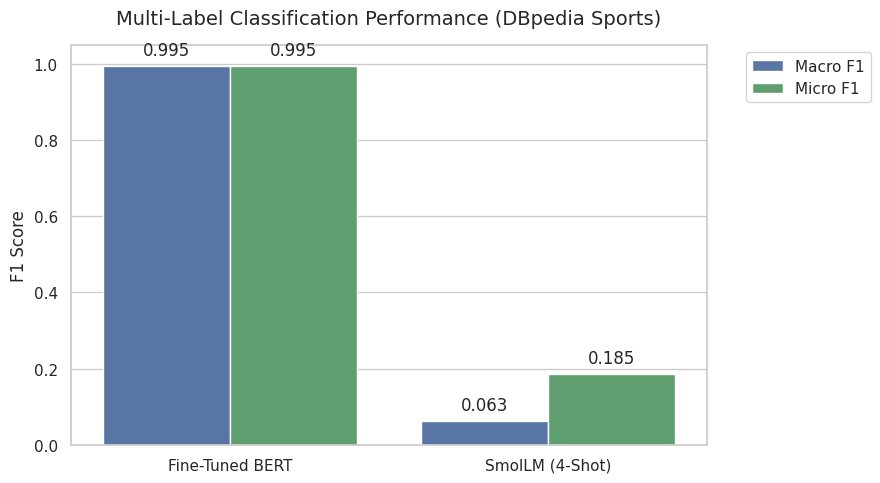

In [ ]:
# Extract Macro and Micro F1 scores
bert_macro = bert_test_results.get("eval_macro_f1", 0.0)
bert_micro = bert_test_results.get("eval_micro_f1", 0.0)

smollm_macro = smollm_results.get("macro_f1", 0.0)
smollm_micro = smollm_results.get("micro_f1", 0.0)

# Format the data for a grouped seaborn barplot
data = {
    "Model & Strategy": ["Fine-Tuned BERT", "Fine-Tuned BERT", "SmolLM (4-Shot)", "SmolLM (4-Shot)"],
    "Metric": ["Macro F1", "Micro F1", "Macro F1", "Micro F1"],
    "Score": [bert_macro, bert_micro, smollm_macro, smollm_micro]
}
df = pd.DataFrame(data)

# Plot scores
plt.figure(figsize=(9, 5))
sns.set_theme(style="whitegrid")

ax = sns.barplot(
    x="Model & Strategy",
    y="Score",
    hue="Metric",
    data=df,
    palette=['#4C72B0', '#55A868']
)

plt.title('Multi-Label Classification Performance (DBpedia Sports)', fontsize=14, pad=15)
plt.xlabel('', fontsize=12)
plt.ylabel('F1 Score', fontsize=12)
plt.ylim(0, 1.05)
plt.legend(title='', bbox_to_anchor=(1.05, 1), loc='upper left')

for container in ax.containers:
    ax.bar_label(container, fmt='%.3f', padding=5)

plt.tight_layout()
plt.savefig('multilabel_results_micro_macro.png', dpi=300, bbox_inches='tight')
plt.show()

## 11.1 Corpus insights
The DBClasses dataset contained various categories of Wikipedia articles. A complete ontology of the different classes was also available (https://web.informatik.uni-mannheim.de/DBpediaAsTables/DBpedia-en-2016-04/DBpediaClasses.htm), which helped forming the 11 sports-related labels to be included.

## 11.2 Results
As can be seen from the visualization above, the fine-tuned BERT model reached near perfect F1 scores for the multi-label task. Because the training set included partial matches and out-of-context examples, the model was able to learn the specific contextual boundaries of the different labels<br><br>
The 4-shot prompting results with the SmolLM show that the model significantly struggled to adapt to the strict multi-label output constraints using only prompt engineering. The difference between the Macro and Micro F1 scores show that when the model actually happened to label the example correctly, it was heavily biased to the broad and frequent labels (such as "Agent" or "Place"), but struggled to identify the more specific labels.<br><br>
These results support the findings of [1], that fine-tuned encoder-only models can be vastly superior compared to decoder-only models in specific text classification tasks.

## 11.3. Relation to expected performance

There was no direct baseline available for this specific research setting with a limited number of DBClasses labels, but the BERT model clearly exceeded the 0.975 baseline outlined by [1] that the BERT model reached on the whole dataset.

# 12. References
[1] Scherp, A., Diera, A., Karl, F., Lin, B. X., Khera, B., Meuser, T., Singhal, T., & Poech, L. G. (2026). Are We Really Making Much Progress in Text Classification? a Comparative Review. IEEE Transactions on Knowledge and Data Engineering, 1–20. https://doi.org/10.1109/TKDE.2026.3735248<br><br>

[2] Zhang, Z., Zeng, W., Tang, J., Wang, J., & Zhao, X. (2025). Yes is harder than no: A behavioral study of framing effects in large language models across downstream tasks. In Proceedings of the 34th ACM International Conference on Information and Knowledge Management, 4304-4314. https://doi.org/10.1145/3746252.3761350 <br><br>

[3] Ashraf, H., Danish, S. M., Rahman, S., & Sattar, Z. (2025). Toward Green Code: Prompting Small Language Models for Energy-Efficient Code Generation. 2025 3rd International Conference on Foundation and Large Language Models (FLLM), 606–612. https://doi.org/10.1109/FLLM67465.2025.11391183<br><br>

[4] Sguotti, G., Troia, S., & Maier, G. (2026). Agentic AI CPE: Traffic Steering Via Small Language Models and Zero-Shot Forecasting. IEEE Conference on Network Softwarization (NetSoft) (Online), 99–107. https://doi.org/10.1109/NetSoft70012.2026.11603511<br><br>

[5] Han, D., Xia, M., Diaz, D. M., Kessler, S., Mallick, A., Zhang, X., Garcia, M. D. C. H., Xu, J., Rühle, V., & Rajmohan, S. (2025). Enhancing Reasoning Capabilities of Small Language Models with Blueprints and Prompt Template Search. https://doi.org/10.48550/arxiv.2506.08669<br><br>

[6] Prottasha, N. J., Sami, A. A., Kowsher, M., Murad, S. A., Bairagi, A. K., Masud, M., & Baz, M. (2022). Transfer Learning for Sentiment Analysis Using BERT Based Supervised Fine-Tuning. Sensors (Basel, Switzerland), 22(11), 4157. https://doi.org/10.3390/s22114157<br><br>

[7] Basahel, A. M., Giriyappa, S. H., Alam, F., Alnazzawi, T. S. M., Qamar, S., & Abi Sen, A. A. (2026). A Resource-Efficient Approach to Fine-Tuning a BERT-Base Model for Sentiment Analysis. Computers (Basel), 15(3), 159. https://doi.org/10.3390/computers15030159 <br><br>

[8] Chien Van Nguyen, Xuan Shen, Ryan Aponte, Yu Xia, Samyadeep Basu, Zhengmian Hu, Jian Chen, Mihir Parmar, Sasidhar Kunapuli, Joe Barrow, Junda Wu, Ashish Singh, Yu Wang, Jiuxiang Gu, Nesreen K. Ahmed, Nedim Lipka, Ruiyi Zhang, Xiang Chen, Tong Yu, Sungchul Kim, Hanieh Deilamsalehy, Namyong Park, Michael Rimer, Zhehao Zhang, Huanrui Yang, Puneet Mathur, Gang Wu, Franck Dernoncourt, Ryan A. Rossi, & Thien Huu Nguyen (2025). A Survey on Small Language Models. Proceedings of the 15th International Conference on Recent Advances in Natural Language Processing - Natural Language Processing in the Generative AI Era, 807–821, Varna, Bulgaria. INCOMA Ltd., Shoumen, Bulgaria. https://doi.org/10.26615/978-954-452-098-4-093 <br><br>

[9] Zhang, X., Zhao, J., & LeCun, Y. (2015). Character-level convolutional networks for text classification. Advances in neural information processing systems, 28.<br><br>

[10] Baseline performance Silcock, E., & Löwe, S. (2026). Active Learning for Finding a Needle in a Haystack. https://doi.org/10.48550/arxiv.2610.15165 <br><br>


[11] Eltahier, S., Dawood, O., & Saeed, I. (2025). BERT Fine-Tuning for Software Requirement Classification: Impact of Model Components and Dataset Size. Information (Basel), 16(11), 981. https://doi.org/10.3390/info16110981 <br><br>

[12] Opitz, J., & Burst, S. (2019). Macro F1 and Macro F1. https://doi.org/10.48550/arxiv.1911.03347 <br><br>

[13] Lipton, Z. C., Elkan, C., & Naryanaswamy, B. (2014). Optimal Thresholding of Classifiers to Maximize F1 Measure. In T. Calders, F. Esposito, E. Hüllermeier, & R. Meo (Eds.), Machine Learning and Knowledge Discovery in Databases (Vol. 8725, pp. 225–239). Springer Berlin / Heidelberg. https://doi.org/10.1007/978-3-662-44851-9_15 <br><br>

[14] Thakur, G., Srivastava, J., Tyagi, A., Kanushriya, & Kaur, J. (2026). Cross-lingual transfer learning for fake news detection: leveraging high-resource language for low-resource adaptation. Neural Computing & Applications, 38(16), Article 677. https://doi.org/10.1007/s00521-026-12430-3<br><br>

[15] Groves, E., Wang, M., Abdulle, Y., Kunz, H., Hoelscher-Obermaier, J., Wu, R., & Wu, H. (2023). Benchmarking and Analyzing In-context Learning, Fine-tuning and Supervised Learning for Biomedical Knowledge Curation: a focused study on chemical entities of biological interest. https://doi.org/10.48550/arxiv.2312.12989 <br><br>

[16] Gkouti, N., Malakasiotis, P., Toumpis, S., & Androutsopoulos, I. (2024). Should I try multiple optimizers when fine-tuning a pre-trained Transformer for NLP tasks? Should I tune their hyperparameters?. In Proceedings of the 18th Conference of the European Chapter of the Association for Computational Linguistics (Volume 1: Long Papers), 2555-2574. https://doi.org/10.18653/v1/2024.eacl-long.157 <br><br>

[17] Zhang, J., Chang, W., Yu, H., & Dhillon, I. S. (2021). Fast Multi-Resolution Transformer Fine-tuning for Extreme Multi-label Text Classification. https://doi.org/10.48550/arxiv.2110.00685 <br><br>

[18] Altalhan, M., Algarni, A., & Alouane, M. T.-H. (2025). Imbalanced Data problem in Machine Learning: A review. IEEE Access, 13, 1–1. https://doi.org/10.1109/ACCESS.2025.3531662


